In [1]:
from pathlib import Path

import holidays
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_parquet(Path("..") / "data" / "processed" / "eco2mix_national.parquet")
df.info()
print(df["date_heure"].min(), "->", df["date_heure"].max())
df.describe()

Matplotlib is building the font cache; this may take a moment.


<class 'pandas.DataFrame'>
RangeIndex: 268796 entries, 0 to 268795
Data columns (total 2 columns):
 #   Column        Non-Null Count   Dtype              
---  ------        --------------   -----              
 0   date_heure    268796 non-null  datetime64[us, UTC]
 1   consommation  134397 non-null  float64            
dtypes: datetime64[us, UTC](1), float64(1)
memory usage: 4.1 MB
2019-01-01 00:00:00+00:00 -> 2026-08-31 21:45:00+00:00


,consommation
count,134397.000000
mean,51351.572587
std,10989.031356
min,29124.000000
25%,43213.000000
50%,49630.000000
75%,58463.000000
max,90236.000000


In [2]:
df["minute"] = df["date_heure"].dt.minute

# Nombre de NaN et nombre total de lignes, pour chaque valeur de minute
resume = pd.DataFrame({
    "nb_lignes": df.groupby("minute").size(),
    "nb_nan": df["consommation"].isna().groupby(df["minute"]).sum(),
})
print(resume)

        nb_lignes  nb_nan
minute                   
0           67199       1
15          67199   67199
30          67199       0
45          67199   67199


In [3]:
# On garde seulement les minutes 0 et 30 (le pas réel des données définitives)
demi_heure = df[df["date_heure"].dt.minute.isin([0, 30])]
serie = demi_heure.set_index("date_heure")["consommation"]
print(len(serie), "points demi-horaires,", serie.isna().sum(), "NaN restants")

134398 points demi-horaires, 1 NaN restants


In [4]:
# 1. Horodatages attendus : un point toutes les 30 min entre la 1re et la dernière date
attendu = pd.date_range(start=serie.index.min(), end=serie.index.max(), freq="30min")
manquants = attendu.difference(serie.index)
print("Attendus :", len(attendu))
print("Présents :", len(serie))
print("Manquants :", len(manquants))
if len(manquants) > 0:
    print(manquants[:20])   # les 20 premiers trous, pour les inspecter

# 2. Doublons
print("Doublons :", serie.index.duplicated().sum())

# 3. NaN restants aux minutes 0 et 30 (de vrais trous de mesure)
print("NaN restants :", serie.isna().sum())
if serie.isna().sum() > 0:
    print(serie[serie.isna()].head(20))

Attendus : 134396
Présents : 134398
Manquants : 14
DatetimeIndex(['2019-10-27 00:00:00+00:00', '2019-10-27 00:30:00+00:00',
               '2020-10-25 00:00:00+00:00', '2020-10-25 00:30:00+00:00',
               '2021-10-31 00:00:00+00:00', '2021-10-31 00:30:00+00:00',
               '2022-10-30 00:00:00+00:00', '2022-10-30 00:30:00+00:00',
               '2023-10-29 00:00:00+00:00', '2023-10-29 00:30:00+00:00',
               '2024-10-27 00:00:00+00:00', '2024-10-27 00:30:00+00:00',
               '2025-10-26 00:00:00+00:00', '2025-10-26 00:30:00+00:00'],
              dtype='datetime64[us, UTC]', freq=None)
Doublons : 16
NaN restants : 1
date_heure
2025-12-31 23:00:00+00:00   NaN
Name: consommation, dtype: float64


In [6]:
# UTC pour stocker, heure de Paris pour analyser le rythme de vie
paris = serie.tz_convert("Europe/Paris")

In [7]:
# Prédictions avant exécution :
#   26/10/2025 (heure d'hiver) -> 50 points (journée de 25 h)
#   30/03/2025 (heure d'été)   -> 46 points (journée de 23 h)
#   19/10/2025 (normal)        -> 48 points
for jour in ["2025-10-26", "2025-03-30", "2025-10-19"]:
    print(jour, ":", len(paris.loc[jour]), "points")

2025-10-26 : 48 points
2025-03-30 : 48 points
2025-10-19 : 48 points


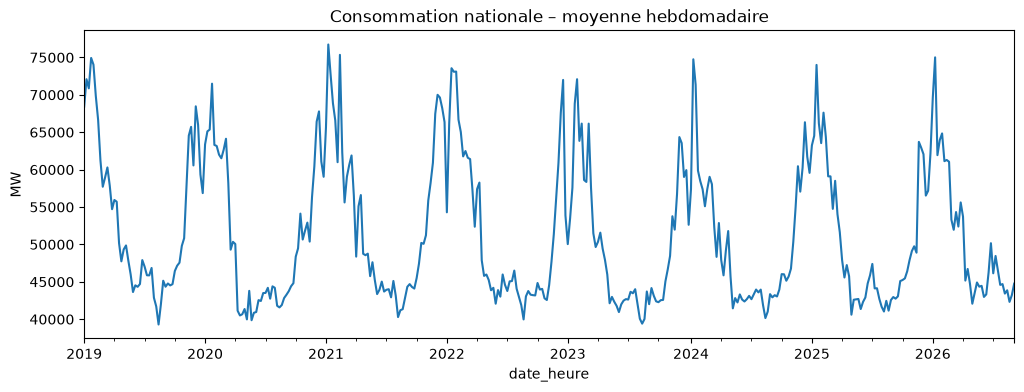

In [8]:
fig, ax = plt.subplots(figsize=(12, 4))
serie.resample("W").mean().plot(ax=ax)
ax.set_title("Consommation nationale – moyenne hebdomadaire")
ax.set_ylabel("MW")
plt.show()

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_10708\1245861271.py:3: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  profil["week_end"] = profil.index.dayofweek >= 5   # 5 = samedi, 6 = dimanche


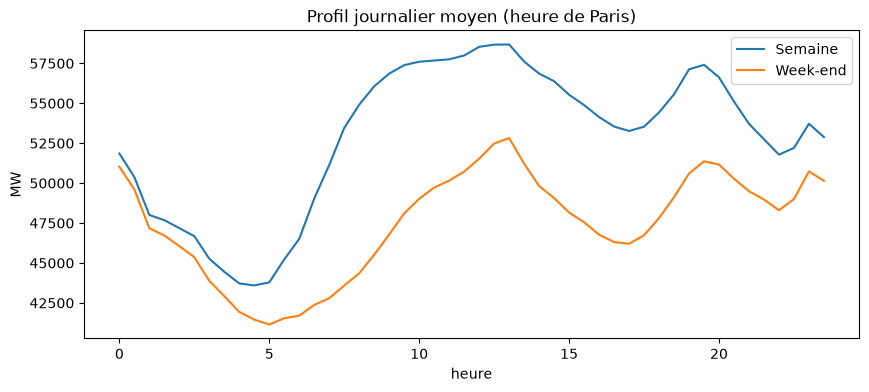

In [9]:
profil = paris.to_frame()
profil["heure"] = profil.index.hour + profil.index.minute / 60
profil["week_end"] = profil.index.dayofweek >= 5   # 5 = samedi, 6 = dimanche

ax = (profil.groupby(["heure", "week_end"])["consommation"]
      .mean().unstack().plot(figsize=(10, 4)))
ax.set_title("Profil journalier moyen (heure de Paris)")
ax.set_ylabel("MW")
ax.legend(["Semaine", "Week-end"])
plt.show()

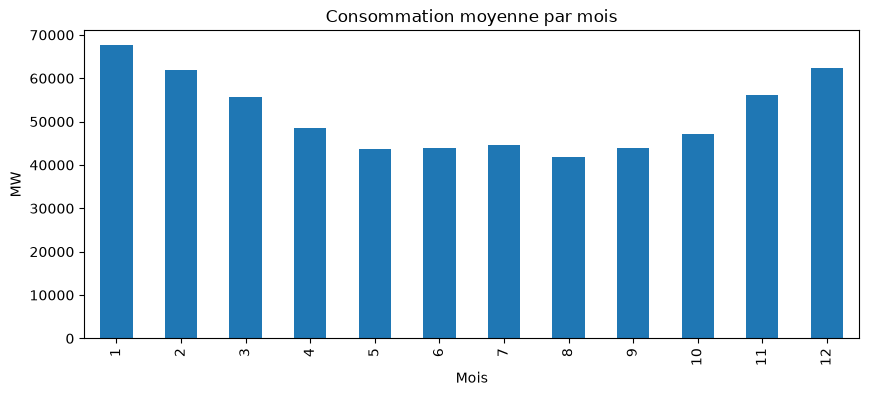

In [10]:
ax = paris.groupby(paris.index.month).mean().plot(kind="bar", figsize=(10, 4))
ax.set_title("Consommation moyenne par mois")
ax.set_xlabel("Mois")
ax.set_ylabel("MW")
plt.show()

In [11]:
jours = paris.resample("D").mean().to_frame("conso_moy")
feries_fr = holidays.France(years=range(2019, 2027))
jours["ferie"] = [jour.date() in feries_fr for jour in jours.index]
jours["jour_semaine"] = jours.index.dayofweek

# On compare uniquement les jours de semaine (lundi à vendredi), fériés ou non
jours_ouvres = jours[jours["jour_semaine"] < 5]
print(jours_ouvres.groupby("ferie")["conso_moy"].mean())
print("Moyenne des dimanches :", jours[jours["jour_semaine"] == 6]["conso_moy"].mean())

ferie
False    53192.066956
True     44690.308961
Name: conso_moy, dtype: float64
Moyenne des dimanches : 46577.49890625


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_10708\160330092.py:4: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  jours["jour_semaine"] = jours.index.dayofweek


In [12]:
NOMS_MOIS = {1: "janvier", 2: "février", 3: "mars", 4: "avril", 5: "mai", 6: "juin",
             7: "juillet", 8: "août", 9: "septembre", 10: "octobre", 11: "novembre", 12: "décembre"}

def format_heure(h: float) -> str:
    """Convertit 19.5 en '19h30'."""
    return f"{int(h)}h{int(round((h % 1) * 60)):02d}"

# 1. Qualité
nb_manquants = len(manquants)
nb_doublons = int(serie.index.duplicated().sum())
nb_nan = int(serie.isna().sum())

# 2. Changement d'heure
pts_hiver = len(paris.loc["2025-10-26"])
pts_ete = len(paris.loc["2025-03-30"])
pts_normal = len(paris.loc["2025-10-19"])

# 3. Profil journalier (jours de semaine)
profil_semaine = profil[~profil["week_end"]].groupby("heure")["consommation"].mean()
h_pic, h_creux = profil_semaine.idxmax(), profil_semaine.idxmin()
moy_semaine = profil.loc[~profil["week_end"], "consommation"].mean()
moy_we = profil.loc[profil["week_end"], "consommation"].mean()
ecart_we_pct = (moy_semaine - moy_we) / moy_semaine * 100

# 4. Saisonnalité annuelle
moyennes_mois = paris.groupby(paris.index.month).mean()
m_max, m_min = moyennes_mois.idxmax(), moyennes_mois.idxmin()
ecart_jan_jul = (moyennes_mois.loc[1] - moyennes_mois.loc[7]) / moyennes_mois.loc[7] * 100

# 5. Jours fériés
moy_ouvre = jours_ouvres.loc[~jours_ouvres["ferie"], "conso_moy"].mean()
moy_ferie = jours_ouvres.loc[jours_ouvres["ferie"], "conso_moy"].mean()

moy_dimanche = jours.loc[jours["jour_semaine"] == 6, "conso_moy"].mean()

# Rédaction (sortie à copier dans une cellule Markdown)
print(f"""## Observations

1. **Qualité** : {nb_manquants} horodatages manquants, {nb_doublons} doublons, {nb_nan} NaN aux minutes 0 et 30. Le pas réel est de 30 min (les minutes 15 et 45 sont vides).
   → Impact : on travaille au pas demi-horaire ; les trous éventuels devront être traités avant de calculer les décalages (lags).

2. **Changement d'heure** : {pts_hiver} points le 26/10/2025, {pts_ete} le 30/03/2025, {pts_normal} un dimanche normal.
   → Impact : stockage en UTC, variables calendaires calculées en heure de Paris.

3. **Profil journalier** : pic vers {format_heure(h_pic)}, creux vers {format_heure(h_creux)} en semaine ; le week-end est {ecart_we_pct:.1f} % plus bas que la semaine.
   → Impact : variables `heure` et `jour_semaine`.

4. **Saisonnalité annuelle** : mois le plus haut = {NOMS_MOIS[m_max]} ({moyennes_mois.loc[m_max]:,.0f} MW), le plus bas = {NOMS_MOIS[m_min]} ({moyennes_mois.loc[m_min]:,.0f} MW) ; janvier est {ecart_jan_jul:.1f} % au-dessus de juillet.
   → Impact : variable `mois` ; forte thermosensibilité, donc la température serait une variable utile.

5. **Jours fériés** : jour ouvré normal ≈ {moy_ouvre:,.0f} MW, jour férié en semaine ≈ {moy_ferie:,.0f} MW, dimanche ≈ {moy_dimanche:,.0f} MW.
   → Impact : variable `est_ferie`, car un jour férié se comporte presque comme un dimanche.
""")

## Observations

1. **Qualité** : 14 horodatages manquants, 16 doublons, 1 NaN aux minutes 0 et 30. Le pas réel est de 30 min (les minutes 15 et 45 sont vides).
   → Impact : on travaille au pas demi-horaire ; les trous éventuels devront être traités avant de calculer les décalages (lags).

2. **Changement d'heure** : 48 points le 26/10/2025, 48 le 30/03/2025, 48 un dimanche normal.
   → Impact : stockage en UTC, variables calendaires calculées en heure de Paris.

3. **Profil journalier** : pic vers 13h00, creux vers 4h30 en semaine ; le week-end est 10.2 % plus bas que la semaine.
   → Impact : variables `heure` et `jour_semaine`.

4. **Saisonnalité annuelle** : mois le plus haut = janvier (67,662 MW), le plus bas = août (41,926 MW) ; janvier est 52.0 % au-dessus de juillet.
   → Impact : variable `mois` ; forte thermosensibilité, donc la température serait une variable utile.

5. **Jours fériés** : jour ouvré normal ≈ 53,192 MW, jour férié en semaine ≈ 44,690 MW, dimanche ≈ 46,577 MW